## 1. Conhecer os Dados e o Problema de Negócio

### Como a equipe de retenção usará o modelo
Em vez de oferecer descontos para toda a base (o que reduz a margem de lucro) ou agir apenas quando o cliente liga para cancelar, a equipe de retenção pode usar a probabilidade de cancelamento gerada pela rede neural para **priorizar contatos preventivos**. 

Clientes classificados com alto risco de cancelamento (especialmente os de maior valor de mensalidade) entram no topo da fila de atendimento para receber ofertas direcionadas, revisão de plano ou suporte proativo antes da perda de receita.

### Fonte e estrutura dos dados
* **Fonte:** Dataset público *Telco Customer Churn* (IBM Sample Data Sets, disponibilizado no Kaggle: `blastchar/telco-customer-churn`).
* **O que cada linha representa:** Um cliente único da operadora de telecomunicações, contendo informações demográficas, serviços contratados (internet, telefone, suporte), tipo de contrato, forma de pagamento e valores cobrados.
* **Variável alvo (`Churn`):** Indica se o cliente cancelou o serviço no último mês (`Yes` = cancelou / `1`; `No` = permaneceu ativo / `0`).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42

# Carregar base obtida da execução do arquivo "download_csv.py"
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# O conjunto df_teste fica reservado no "cofre" e não é usado nos gráficos abaixo
df_resto, df_teste = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df["Churn"]
)
df_treino, df_valid = train_test_split(
    df_resto, test_size=0.25, random_state=SEED, stratify=df_resto["Churn"]
)

print(f"Total: {len(df)} | Treino: {len(df_treino)} | Validação: {len(df_valid)} | Teste (cofre): {len(df_teste)}")

# Valores Vazios
vazios_treino = df_treino["TotalCharges"].str.strip() == ""
print(f"\nValores vazios em TotalCharges no treino: {vazios_treino.sum()}")
print("Tempo de casa (tenure) desses registros no treino:")
print(df_treino.loc[vazios_treino, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

Total: 7043 | Treino: 4225 | Validação: 1409 | Teste (cofre): 1409

Valores vazios em TotalCharges no treino: 7
Tempo de casa (tenure) desses registros no treino:
      customerID  tenure  MonthlyCharges TotalCharges
6670  4075-WKNIU       0           73.35             
3826  3213-VVOLG       0           25.35             
3331  7644-OMVMY       0           19.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
4380  2520-SGTTA       0           20.00             
6754  2775-SEFEE       0           61.90             


### Tratamento de valores vazios em `TotalCharges`
A coluna `TotalCharges` foi carregada como texto (`object`) porque contém espaços em branco (`" "`) em alguns registros. Ao inspecionar esses casos no conjunto de treino, verifica-se que todos correspondem a clientes novos com `tenure == 0` (ainda não completaram o primeiro mês de faturamento).

**Regra de tratamento adotada:**
1. Converter a coluna `TotalCharges` para formato numérico (`pd.to_numeric(..., errors="coerce")`), transformando os espaços em branco em `NaN`.
2. Preencher os valores `NaN` com `0.0`, refletindo o total cobrado até o momento para clientes com `tenure == 0`.
3. Aplicar essa mesma regra determinística aos conjuntos de treino, validação e teste sem risco de vazamento de dados.

In [2]:
def tratar_base(dados):
    d = dados.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0.0)
    d["Churn_num"] = d["Churn"].map({"No": 0, "Yes": 1})
    return d

df_treino = tratar_base(df_treino)
df_valid = tratar_base(df_valid)
df_teste = tratar_base(df_teste)

print("Nulos restantes em TotalCharges (treino):", df_treino["TotalCharges"].isna().sum())
print(f"Taxa de Churn no treino: {df_treino['Churn_num'].mean()*100:.1f}%")

Nulos restantes em TotalCharges (treino): 0
Taxa de Churn no treino: 26.5%


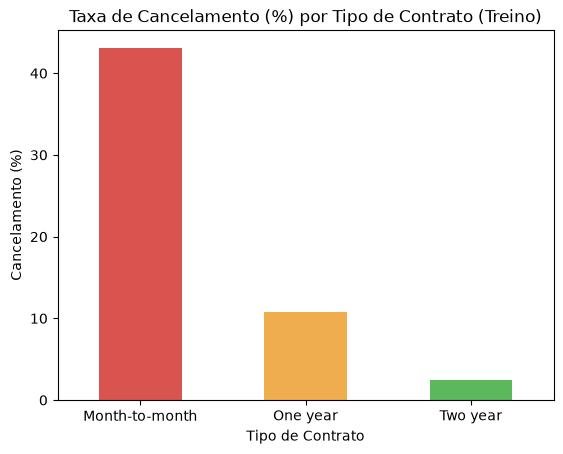

In [3]:
churn_contrato = df_treino.groupby("Contract")["Churn_num"].mean() * 100
churn_contrato.plot(kind="bar", color=["#d9534f", "#f0ad4e", "#5cb85c"])
plt.title("Taxa de Cancelamento (%) por Tipo de Contrato (Treino)")
plt.ylabel("Cancelamento (%)")
plt.xlabel("Tipo de Contrato")
plt.xticks(rotation=0)
plt.show()

**Conclusão 1:** No conjunto de treino, clientes com contrato mensal (*Month-to-month*) apresentam uma taxa de cancelamento drasticamente superior à de clientes com contratos de 1 ou 2 anos. A equipe de retenção deve focar ações de fidelização e migração de plano prioritariamente nesse grupo.

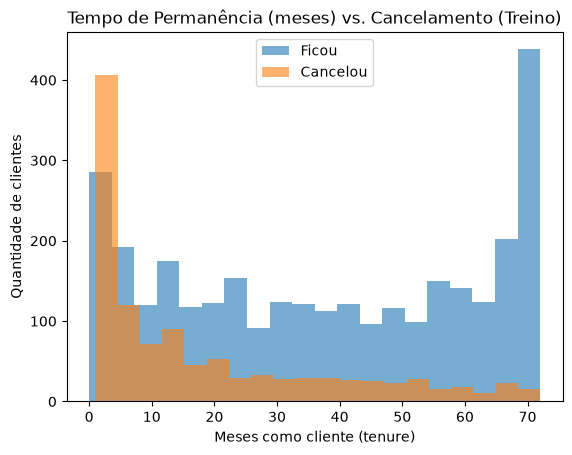

In [4]:
df_treino[df_treino["Churn"] == "No"]["tenure"].plot(kind="hist", alpha=0.6, bins=20, label="Ficou")
df_treino[df_treino["Churn"] == "Yes"]["tenure"].plot(kind="hist", alpha=0.6, bins=20, label="Cancelou")
plt.title("Tempo de Permanência (meses) vs. Cancelamento (Treino)")
plt.xlabel("Meses como cliente (tenure)")
plt.ylabel("Quantidade de clientes")
plt.legend()
plt.show()

**Conclusão 2:** A maior concentração de cancelamentos ocorre nos primeiros meses de relacionamento (especialmente até o 12º mês). Quanto maior o tempo de casa do cliente, menor a probabilidade de saída, o que indica que o acompanhamento preventivo tem maior impacto no período inicial da jornada.